# Evaluation Figures

This notebook visualizes exact vs semantic agreement metrics from `results/evaluation_report.json`.

Figures are saved to `results/figures/`. The style is configured for Times New Roman and larger font sizes.

In [20]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(
    context="paper",
    style="whitegrid",
    font="Times New Roman",
    font_scale=1.6,
)
palette = sns.color_palette("Set2")

REPORT_PATH = Path("results/evaluation_report.json")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

with REPORT_PATH.open("r", encoding="utf-8") as f:
    report = json.load(f)

exact = report["exact"] if "exact" in report else report
semantic = report.get("semantic")
if semantic is None:
    raise ValueError("This notebook expects a semantic report. Run: python src/evaluate.py --semantic --semantic-threshold 0.85")

VIEWS = ["fields", "values", "field_value_pairs"]
VIEW_LABELS = {
    "fields": "Fields",
    "values": "Values",
    "field_value_pairs": "Field + Value",
}
MODEL_LABELS = {
    "deepseek/deepseek-v4-flash": "DeepSeek",
    "qwen/qwen3.5-flash-02-23": "Qwen 3.5",
    "qwen/qwen3.6-flash": "Qwen 3.6",
}

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 20,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 16,
    "figure.titlesize": 24,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLORS = {
    "exact": "#4C78A8",
    "semantic": "#F58518",
    "gain": "#54A24B",
}

print("Loaded report:", REPORT_PATH)
print("Common docs:", exact["common_doc_count"])
print("Semantic backend:", semantic["semantic"]["backend"])
print("Semantic threshold:", semantic["semantic"]["threshold"])

Loaded report: results/evaluation_report.json
Common docs: 196
Semantic backend: sentence-transformers/all-MiniLM-L6-v2
Semantic threshold: 0.85


## Helper Functions

In [2]:
def save_figure(fig, name):
    png_path = FIG_DIR / f"{name}.png"
    pdf_path = FIG_DIR / f"{name}.pdf"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved {png_path}")
    print(f"Saved {pdf_path}")


def bar_label(ax, bars, fmt="{:.2f}"):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            fmt.format(height),
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=13,
        )


def grouped_exact_semantic_bars(ax, exact_values, semantic_values, title, ylabel="Score"):
    x = np.arange(len(VIEWS))
    width = 0.36
    b1 = ax.bar(x - width / 2, exact_values, width, label="Exact", color=COLORS["exact"])
    b2 = ax.bar(x + width / 2, semantic_values, width, label="Semantic", color=COLORS["semantic"])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
    ax.set_ylim(0, max(max(exact_values), max(semantic_values), 0.01) * 1.22)
    ax.grid(axis="y", alpha=0.25)
    bar_label(ax, b1)
    bar_label(ax, b2)
    return ax


def pairwise_matrix(report_obj, view, metric_key):
    models = report_obj["models"]
    matrix = np.eye(len(models))
    for pair in report_obj["pairwise"]:
        i = models.index(pair["model_a"])
        j = models.index(pair["model_b"])
        value = pair["averages"][view][metric_key]
        matrix[i, j] = value
        matrix[j, i] = value
    return models, matrix


def draw_heatmap(ax, matrix, labels, title, vmin=0, vmax=1, cmap="crest"):
    mesh = sns.heatmap(
        matrix,
        ax=ax,
        cmap=sns.color_palette(cmap, as_cmap=True),
        vmin=vmin,
        vmax=vmax,
        square=True,
        annot=True,
        fmt=".2f",
        linewidths=1.2,
        linecolor="white",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"fontsize": 16, "fontweight": "bold"},
    )
    ax.set_title(title, pad=14)
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")

    threshold = (vmin + vmax) / 2
    for text in ax.texts:
        try:
            value = float(text.get_text())
        except ValueError:
            continue
        text.set_color("white" if value >= threshold else "#1f2933")

    return mesh.collections[0]


## Figure 1: Exact vs Semantic Pairwise Agreement

Saved results/figures/fig1_exact_vs_semantic_pairwise.png
Saved results/figures/fig1_exact_vs_semantic_pairwise.pdf


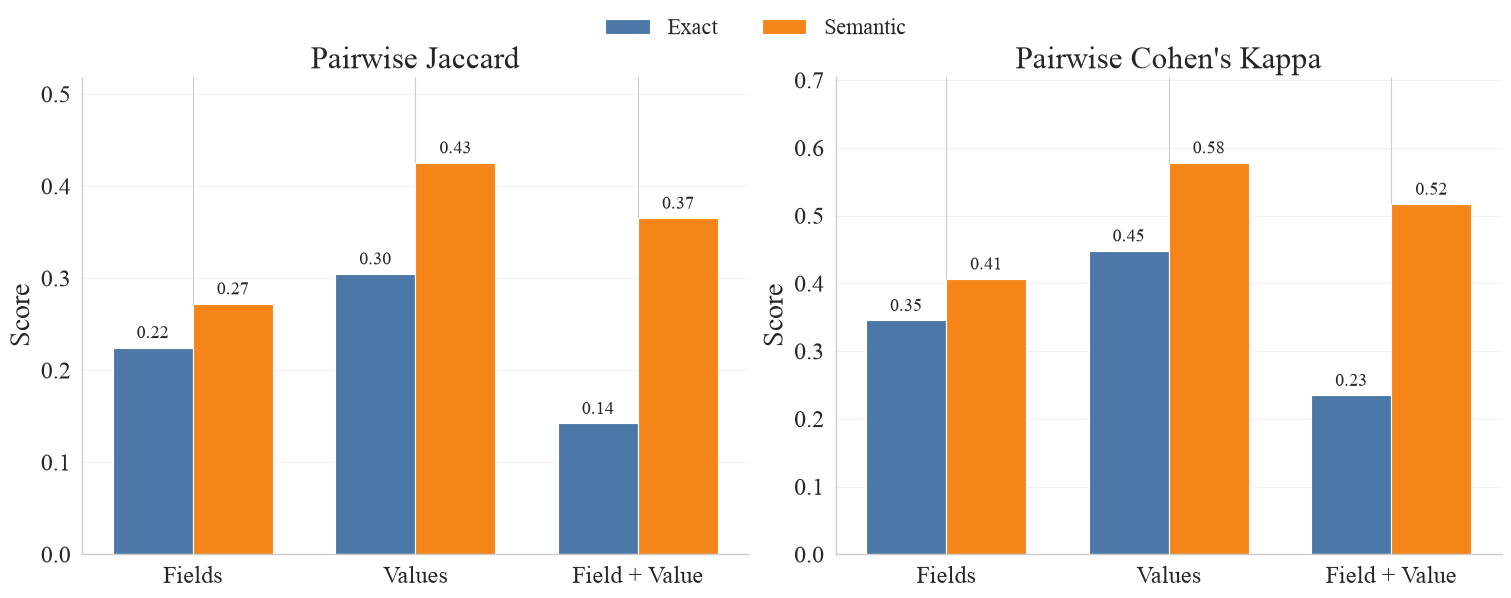

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

exact_j = [exact["overall"]["averages"][v]["average_jaccard"] for v in VIEWS]
sem_j = [semantic["overall"]["averages"][v]["average_jaccard"] for v in VIEWS]
grouped_exact_semantic_bars(axes[0], exact_j, sem_j, "Pairwise Jaccard")

exact_k = [exact["overall"]["averages"][v]["average_cohen_kappa"] for v in VIEWS]
sem_k = [semantic["overall"]["averages"][v]["average_cohen_kappa"] for v in VIEWS]
grouped_exact_semantic_bars(axes[1], exact_k, sem_k, "Pairwise Cohen's Kappa")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
# save_figure(fig, "fig1_exact_vs_semantic_pairwise")
plt.show()

## Figure 2: Exact vs Semantic Multi-Model Agreement

Saved results/figures/fig2_exact_vs_semantic_multimodel.png
Saved results/figures/fig2_exact_vs_semantic_multimodel.pdf


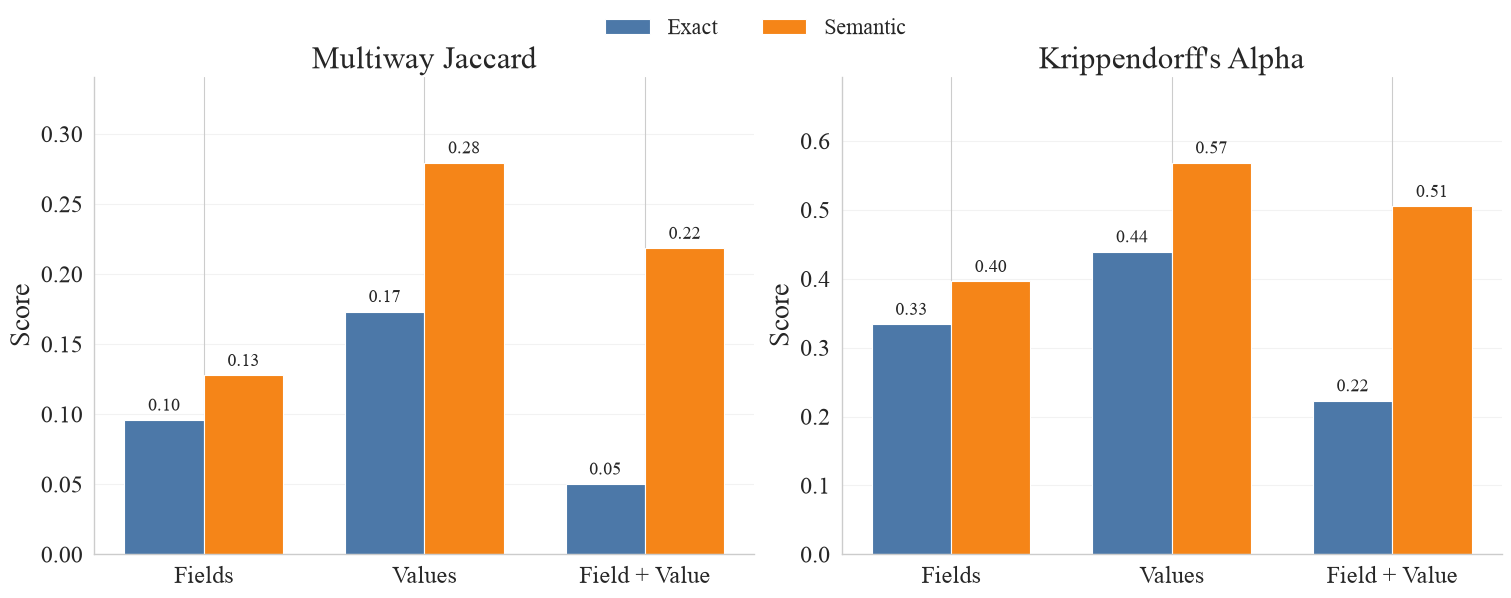

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

exact_mj = [exact["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] for v in VIEWS]
sem_mj = [semantic["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] for v in VIEWS]
grouped_exact_semantic_bars(axes[0], exact_mj, sem_mj, "Multiway Jaccard")

exact_a = [exact["overall_multimodel"]["averages"][v]["average_krippendorff_alpha"] for v in VIEWS]
sem_a = [semantic["overall_multimodel"]["averages"][v]["average_krippendorff_alpha"] for v in VIEWS]
grouped_exact_semantic_bars(axes[1], exact_a, sem_a, "Krippendorff's Alpha")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
# save_figure(fig, "fig2_exact_vs_semantic_multimodel")
plt.show()

## Figure 3: Semantic Gain

Saved results/figures/fig3_semantic_gain.png
Saved results/figures/fig3_semantic_gain.pdf


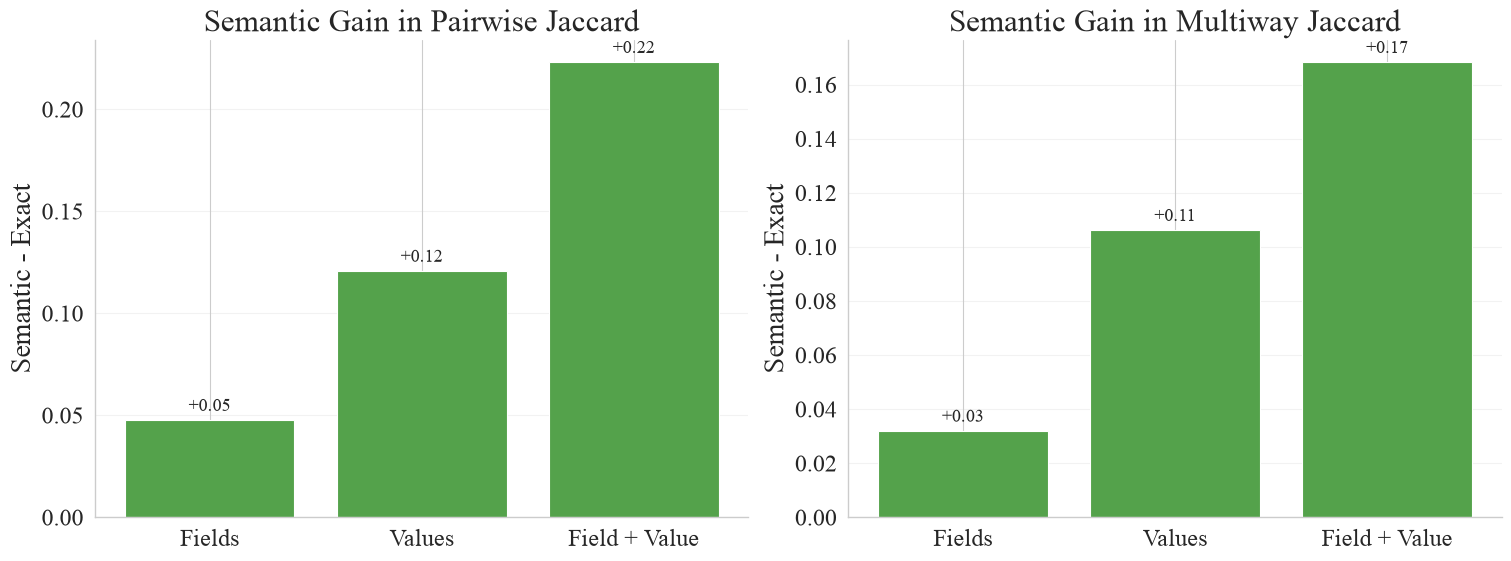

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
x = np.arange(len(VIEWS))

pairwise_gain = [
    semantic["overall"]["averages"][v]["average_jaccard"] - exact["overall"]["averages"][v]["average_jaccard"]
    for v in VIEWS
]
bars = axes[0].bar(x, pairwise_gain, color=COLORS["gain"])
axes[0].set_title("Semantic Gain in Pairwise Jaccard")
axes[0].set_ylabel("Semantic - Exact")
axes[0].set_xticks(x)
axes[0].set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
axes[0].grid(axis="y", alpha=0.25)
bar_label(axes[0], bars, fmt="+{:.2f}")

multi_gain = [
    semantic["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] - exact["overall_multimodel"]["averages"][v]["average_multiway_jaccard"]
    for v in VIEWS
]
bars = axes[1].bar(x, multi_gain, color=COLORS["gain"])
axes[1].set_title("Semantic Gain in Multiway Jaccard")
axes[1].set_ylabel("Semantic - Exact")
axes[1].set_xticks(x)
axes[1].set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
axes[1].grid(axis="y", alpha=0.25)
bar_label(axes[1], bars, fmt="+{:.2f}")

# save_figure(fig, "fig3_semantic_gain")
plt.show()

## Figure 4: Pairwise Jaccard Heatmaps by Agreement View


Saved results/figures/fig4_pairwise_jaccard_heatmap_fields.png
Saved results/figures/fig4_pairwise_jaccard_heatmap_fields.pdf


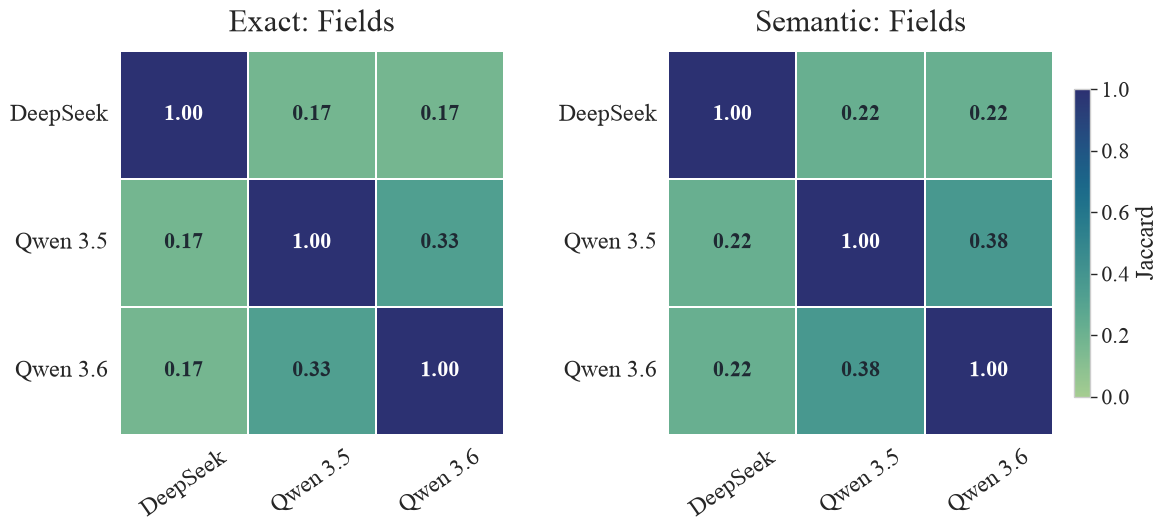

Saved results/figures/fig4_pairwise_jaccard_heatmap_values.png
Saved results/figures/fig4_pairwise_jaccard_heatmap_values.pdf


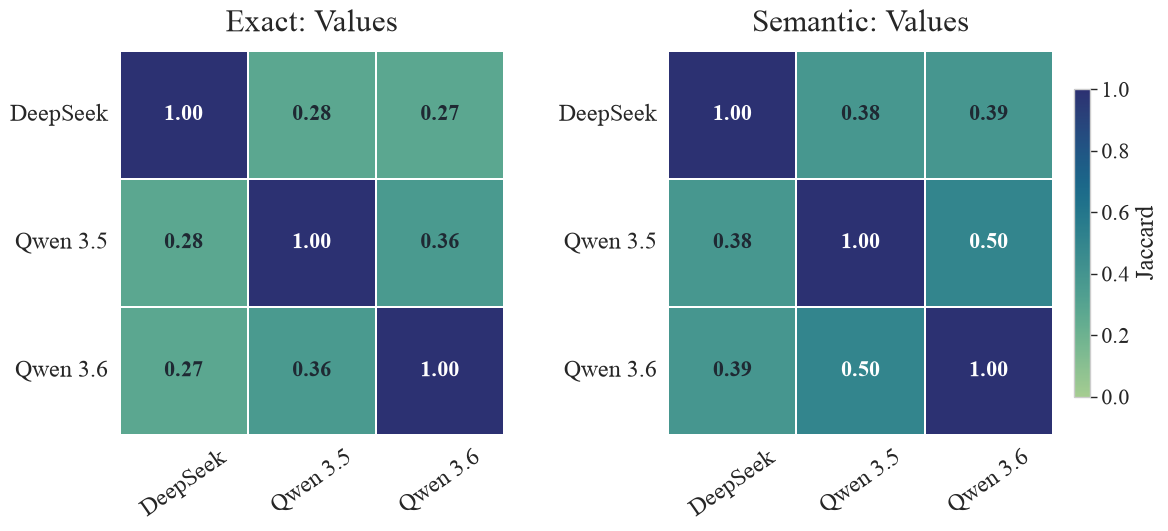

Saved results/figures/fig4_pairwise_jaccard_heatmap_field_value_pairs.png
Saved results/figures/fig4_pairwise_jaccard_heatmap_field_value_pairs.pdf


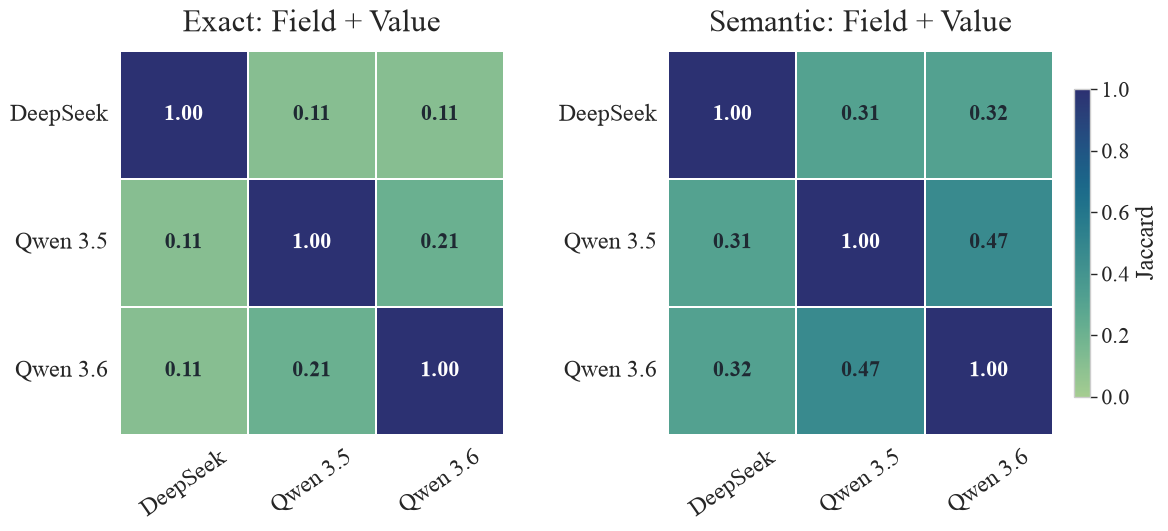

In [ ]:
for view in VIEWS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)

    models, exact_matrix = pairwise_matrix(exact, view, "average_jaccard")
    _, semantic_matrix = pairwise_matrix(semantic, view, "average_jaccard")
    labels = [MODEL_LABELS.get(m, m) for m in models]

    heatmap_artist = draw_heatmap(axes[0], exact_matrix, labels, f"Exact: {VIEW_LABELS[view]}")
    draw_heatmap(axes[1], semantic_matrix, labels, f"Semantic: {VIEW_LABELS[view]}")

    cbar = fig.colorbar(heatmap_artist, ax=axes.ravel().tolist(), shrink=0.8, pad=0.02)
    cbar.set_label("Jaccard", fontsize=18)
    cbar.ax.tick_params(labelsize=16)

#    save_figure(fig, f"fig4_pairwise_jaccard_heatmap_{view}")
    plt.show()


## Figure 5: Semantic Clustering Compression

Saved results/figures/fig5_semantic_clustering_compression.png
Saved results/figures/fig5_semantic_clustering_compression.pdf


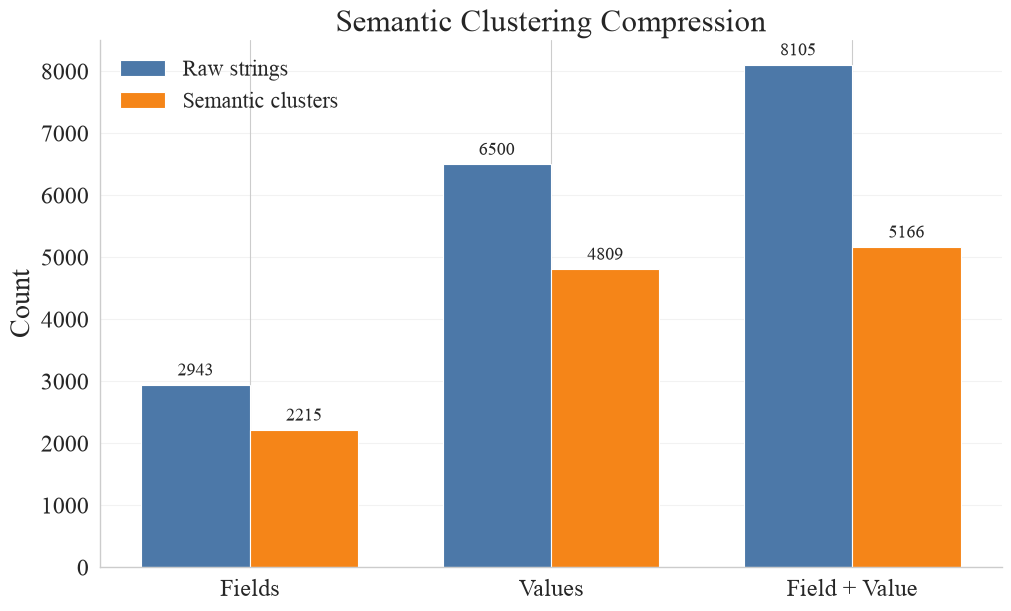

In [ ]:
clusters = semantic["semantic"]["clusters"]
raw_counts = [clusters[v]["raw_item_count"] for v in VIEWS]
cluster_counts = [clusters[v]["cluster_count"] for v in VIEWS]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
x = np.arange(len(VIEWS))
width = 0.36
b1 = ax.bar(x - width / 2, raw_counts, width, label="Raw strings", color=COLORS["exact"])
b2 = ax.bar(x + width / 2, cluster_counts, width, label="Semantic clusters", color=COLORS["semantic"])
ax.set_title("Semantic Clustering Compression")
ax.set_ylabel("Count")
ax.set_xticks(x)
ax.set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
bar_label(ax, b1, fmt="{:.0f}")
bar_label(ax, b2, fmt="{:.0f}")

# save_figure(fig, "fig5_semantic_clustering_compression")
plt.show()

## Figure 6: Semantic Threshold Sensitivity by Metric


Saved results/figures/fig6_semantic_threshold_sensitivity_pairwise_jaccard_mean.png
Saved results/figures/fig6_semantic_threshold_sensitivity_pairwise_jaccard_mean.pdf


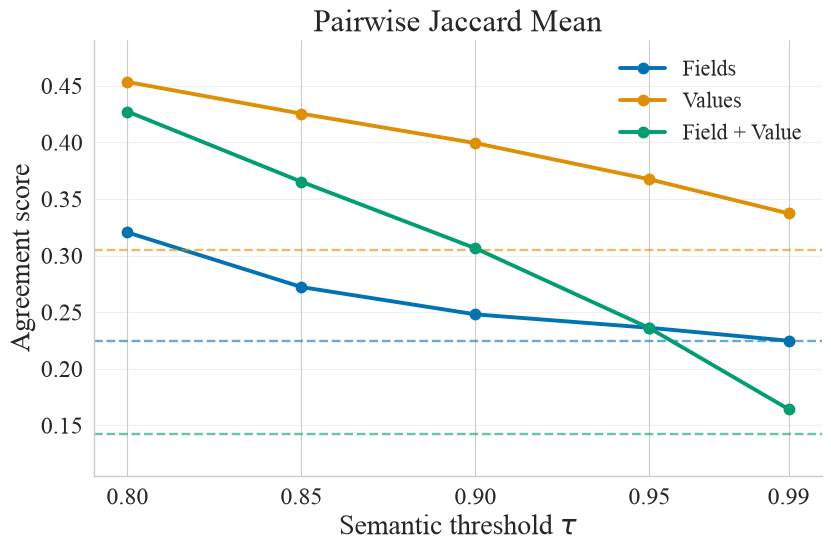

Saved results/figures/fig6_semantic_threshold_sensitivity_multiway_jaccard_mean.png
Saved results/figures/fig6_semantic_threshold_sensitivity_multiway_jaccard_mean.pdf


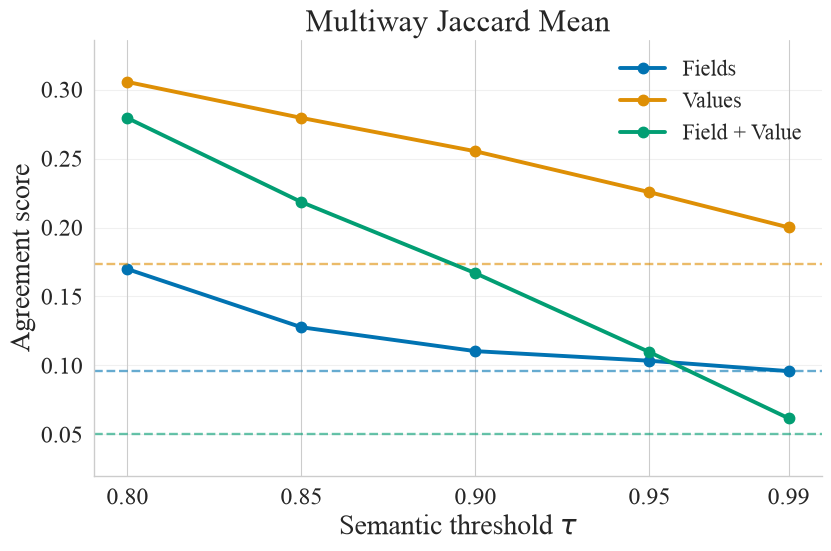

Saved results/figures/fig6_semantic_threshold_sensitivity_krippendorff_alpha_mean.png
Saved results/figures/fig6_semantic_threshold_sensitivity_krippendorff_alpha_mean.pdf


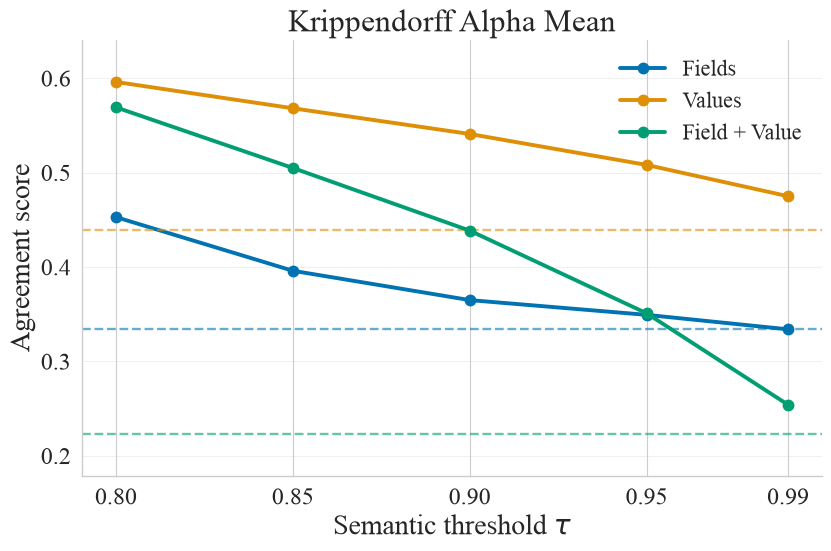

In [ ]:
THRESHOLDS = [0.80, 0.85, 0.90, 0.95, 0.99]
THRESHOLD_REPORTS = {}

for tau in THRESHOLDS:
    report_path = Path(f"results/evaluation_report_semantic_{str(tau).replace('.', 'p')}.json")
    with report_path.open("r", encoding="utf-8") as handle:
        THRESHOLD_REPORTS[tau] = json.load(handle)

baseline_exact = THRESHOLD_REPORTS[0.85]["exact"]
palette = dict(zip(VIEWS, sns.color_palette("colorblind", n_colors=len(VIEWS))))

metric_specs = [
    (
        "Pairwise Jaccard Mean",
        "pairwise_jaccard_mean",
        lambda report, view: report["semantic"]["overall"]["averages"][view]["average_jaccard"],
        lambda report, view: report["overall"]["averages"][view]["average_jaccard"],
    ),
    (
        "Multiway Jaccard Mean",
        "multiway_jaccard_mean",
        lambda report, view: report["semantic"]["overall_multimodel"]["averages"][view]["average_multiway_jaccard"],
        lambda report, view: report["overall_multimodel"]["averages"][view]["average_multiway_jaccard"],
    ),
    (
        "Krippendorff Alpha Mean",
        "krippendorff_alpha_mean",
        lambda report, view: report["semantic"]["overall_multimodel"]["averages"][view]["average_krippendorff_alpha"],
        lambda report, view: report["overall_multimodel"]["averages"][view]["average_krippendorff_alpha"],
    ),
]

def padded_ylim(values, pad_ratio=0.12):
    low = min(values)
    high = max(values)
    span = high - low
    if span == 0:
        span = max(abs(high), 0.1) * 0.1
    pad = span * pad_ratio
    return max(0, low - pad), min(1, high + pad)

for title, file_suffix, semantic_getter, exact_getter in metric_specs:
    fig, ax = plt.subplots(figsize=(8.2, 5.4), constrained_layout=True)
    y_values = []

    for view in VIEWS:
        semantic_scores = [semantic_getter(THRESHOLD_REPORTS[tau], view) for tau in THRESHOLDS]
        exact_score = exact_getter(baseline_exact, view)
        y_values.extend(semantic_scores)
        y_values.append(exact_score)
        color = palette[view]

        ax.plot(
            THRESHOLDS,
            semantic_scores,
            marker="o",
            linewidth=2.8,
            markersize=7.5,
            color=color,
            label=VIEW_LABELS[view],
        )
        ax.axhline(
            exact_score,
            color=color,
            linestyle="--",
            linewidth=1.7,
            alpha=0.6,
        )

    ymin, ymax = padded_ylim(y_values)
    ax.set_ylim(ymin, ymax)
    ax.set_title(title)
    ax.set_xlabel(r"Semantic threshold $\tau$")
    ax.set_ylabel("Agreement score")
    ax.set_xticks(THRESHOLDS)
    ax.grid(axis="y", alpha=0.28)
    ax.legend(loc="best", frameon=False)

    # save_figure(fig, f"fig6_semantic_threshold_sensitivity_{file_suffix}")
    plt.show()
